In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Preping the Dataset

In [33]:
# Creating data set

# A
a =[0, 0, 1, 1, 0, 0,
   0, 1, 0, 0, 1, 0,
   1, 1, 1, 1, 1, 1,
   1, 0, 0, 0, 0, 1,
   1, 0, 0, 0, 0, 1]
# B
b =[0, 1, 1, 1, 1, 0,
   0, 1, 0, 0, 1, 0,
   0, 1, 1, 1, 1, 0,
   0, 1, 0, 0, 1, 0,
   0, 1, 1, 1, 1, 0]
# C
c =[0, 1, 1, 1, 1, 0,
   0, 1, 0, 0, 0, 0,
   0, 1, 0, 0, 0, 0,
   0, 1, 0, 0, 0, 0,
   0, 1, 1, 1, 1, 0]

# Creating labels
Y =[[1, 0, 0],
   [0, 1, 0],
   [0, 0, 1]]

In [34]:
# Convert the dataset from list to array then reshape them to better visualize the shape
a_arr = np.array(a).reshape((5, 6))
b_arr = np.array(b).reshape((5, 6))
c_arr = np.array(c).reshape((5, 6))

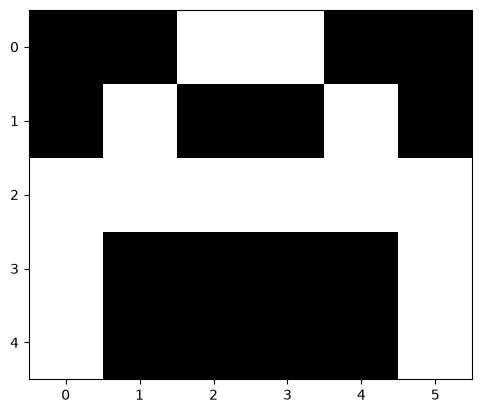

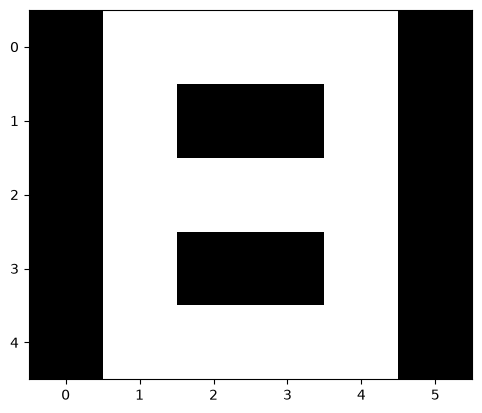

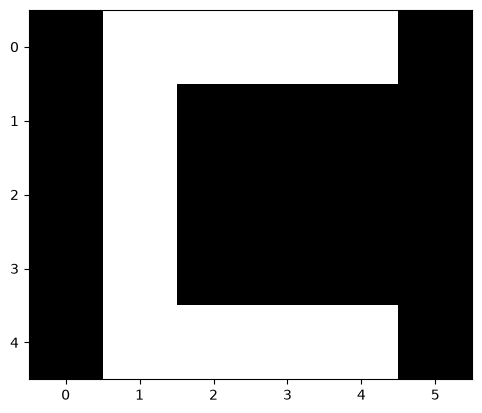

In [35]:
# Visualizing the dataset using Matplotlib
plt.imshow(a_arr, cmap="gray")
plt.show()

plt.imshow(b_arr, cmap="gray")
plt.show()

plt.imshow(c_arr, cmap="gray")
plt.show()


In [36]:
# Make 1 list that has A, B, C of arrays
x = [np.array(a).reshape(1, 30),
    np.array(b).reshape(1, 30),
    np.array(c).reshape(1, 30)]

y = np.array(y)
print(x)
print(y)

[array([[0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
        0, 1, 1, 0, 0, 0, 0, 1]]), array([[0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0,
        1, 0, 0, 1, 1, 1, 1, 0]]), array([[0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 0, 0, 1, 1, 1, 1, 0]])]
[[1 0 0]
 [0 1 0]
 [0 0 1]]


# Neural Network Architecture
- Input layer: 30 neurons, (5, 6)
    - Fully connected
- Hidden layer: 5 neurons
    - Fully connected
- Output layer: 3 neurons, one for each class: A, B, C
# Neural Network Functions
1. Activation function: Sigmoid
2. Feedforward pass
3. Backpropagation
4. Generate weights
5. Loss function: MSE

In [37]:
def sigmoid(z):
    return (1/(1 + (np.exp(-z))))   # e: Euler's number - 2.718


def sigmoid_derivative(z):
    s = sigmoid(z)
    sd = s * (1 - s)
    return sd

def feedforward(x, w1, w2):
    # Dot product of input & weight_1
    z1 = np.dot(x, w1)
    a1 = sigmoid(z1)

    # Dot product of previous activation & weight_2
    z2 = np.dot(a1, w2)
    a2 = sigmoid(z2)

    return a2


def loss_function(y_pred, y_true):
    s = np.square(y_pred - y_true)
    mse = np.mean(s)
    return mse


def generate_weights(no_of_input_connections, no_of_output_connections):
    # The size of the weight matrix is no. of input conns x no. of output conns

    # size = no_of_input_connections * no_of_output_connections
    # weights = np.random.randn(size)
    # weights_matrix = weights.reshape((no_of_input_connections, no_of_output_connections))

    # Better way of the same stuff above is
    return np.random.randn(no_of_input_connections, no_of_output_connections)


def backpropagation(x, w1, w2, learning_rate, actual):
    """
    1. Calculate z, feedforward step
    2. Calcluate error, output - true
    3. Backpropagate
        1. Compute delts, error propagation
        2. Compute weight gradient
    4. Optimization
    """
    z1 = np.dot(x, w1)
    a1 = sigmoid(z1)
    z2 = np.dot(a1, w2)
    a2 = sigmoid(z2)

    # Calculate error propagation
    d2 = (a2 - actual) * sigmoid_derivative(z2)
    d1 = np.dot(d2, w2.T) * sigmoid_derivative(z1)

    # Calculate weight gradients
    w1_gradient = np.dot(x.T, d1)
    w2_gradient = np.dot(a1.T, d2)

    # Optimization, gradient descent
    w1 = w1 - learning_rate * w1_gradient
    w2 = w2 - learning_rate * w2_gradient

    return w1, w2


# Training the Neural Network

In [38]:
# Generate weights
w1 = generate_weights(30, 5)
w2 = generate_weights(5, 3)

print("Weights 1:\n", w1, "\n\n", "Weights 2:\n", w2)

Weights 1:
 [[-0.54796515 -1.69422543 -0.22729729  0.93350548 -2.20391681]
 [-1.16822633 -0.40138295 -0.57634868  0.09905482  0.90614215]
 [ 0.59814764  0.08577042 -0.1802258   0.46951852  1.06805559]
 [ 0.58618875 -1.02624451  0.37158869 -0.59229456 -0.08320535]
 [-0.28418574  0.01101527 -0.92894652 -1.45308722 -0.04640608]
 [-0.48685417  1.0742338   0.12695146 -0.60266907  1.23891642]
 [ 2.22017375 -0.58970128  2.04959175 -0.00481928 -0.07975426]
 [ 2.11190201  1.06409491  0.39491202 -0.1304934   0.216173  ]
 [ 0.6340443  -2.06673747 -1.78503092  1.80222178 -0.28383396]
 [ 2.46543519 -0.51522843  0.36912145  0.26596823 -0.8508207 ]
 [-0.378917   -1.10608987  1.63036436 -0.44661075  0.1459932 ]
 [ 0.00363285 -1.16842832 -0.84851277 -0.24915197 -1.04340303]
 [-1.31512628 -0.90133415  0.89670835 -0.61587392 -0.53426892]
 [ 0.73261424  0.56447149  1.75377401 -0.15532677 -1.40293475]
 [-0.10099376  0.12181394 -1.13907602 -0.60170421  0.03093551]
 [ 2.21216247 -0.48536198  0.11497096  0.14

In [48]:
# Training
def train(x, Y, w1, w2, alpha, epoch):
    loss = []
    accuracy = []
    for i in range(epoch):
        print("=" * 10, f"Epoch: {i + 1}", "=" * 10)
        epoch_loss = np.array([])
        epoch_accuracy = np.array([])
        for j in range(len(x)):
            output = feedforward(x[j], w1, w2)
            epoch_loss = loss_function(output, Y[j])

            w1, w2 = backpropagation(x[j], w1, w2, alpha, Y[j])
            epoch_accuracy = (1 - (np.sum(epoch_loss)/np.size(x))) * 100

            loss.append(epoch_loss)
            accuracy.append(epoch_accuracy)

        print("=" * 10, f"Loss of Epoch: {i + 1}: {epoch_loss}", "=" * 10)
        print("=" * 10, f"Accuracy of Epoch: {i + 1}: {epoch_accuracy}", "=" * 10)

    return loss, accuracy, w1, w2

# Why not just pass in the whole input at once rathe than doing the operations one at a time?
# NumPy specializes in this.

In [52]:
loss, accuracy, w1, w2 = train(x, Y, w1, w2, 0.1, 1000)

========== Epoch: 1 ==========
========== Loss of Epoch: 1: 0.165440280042838 ==========
========== Accuracy of Epoch: 1: 99.81617746661907 ==========
========== Epoch: 2 ==========
========== Loss of Epoch: 2: 0.16252462728672032 ==========
========== Accuracy of Epoch: 2: 99.81941708079253 ==========
========== Epoch: 3 ==========
========== Loss of Epoch: 3: 0.1596909338605396 ==========
========== Accuracy of Epoch: 3: 99.82256562904385 ==========
========== Epoch: 4 ==========
========== Loss of Epoch: 4: 0.15693640669830292 ==========
========== Accuracy of Epoch: 4: 99.82562621477966 ==========
========== Epoch: 5 ==========
========== Loss of Epoch: 5: 0.15425838735848726 ==========
========== Accuracy of Epoch: 5: 99.8286017918239 ==========
========== Epoch: 6 ==========
========== Loss of Epoch: 6: 0.15165433945763895 ==========
========== Accuracy of Epoch: 6: 99.83149517838041 ==========
========== Epoch: 7 ==========
========== Loss of Epoch: 7: 0.14912183812333024 ======

# Plotting Accuracy and Loss

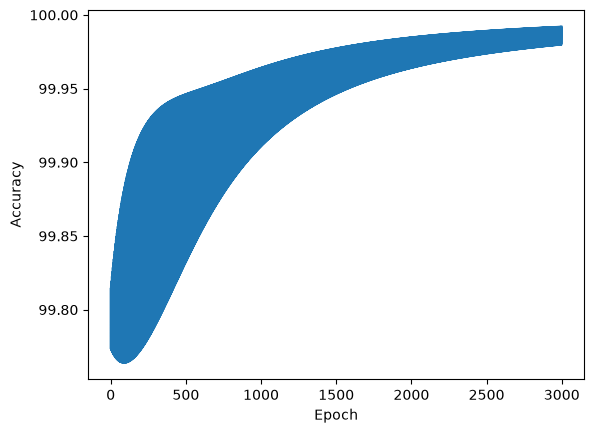

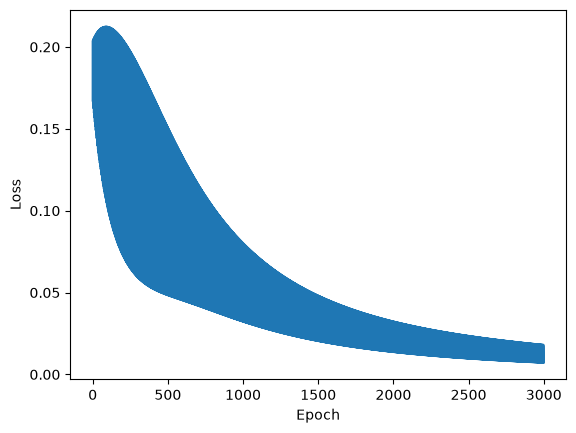

In [53]:
plt.plot(accuracy)
plt.ylabel("Accuracy")
plt.xlabel("Epoch")
plt.show()

plt.plot(loss)
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.show()